<a href="https://colab.research.google.com/github/tanu100/DeepLearning/blob/main/ArtificalNeuralNetwork/Optimizers_in_DL/Momentum_SGD.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [3]:
import pandas as pd
import numpy as np
import seaborn as sns

# Momentum SG

Velocity(t)= Prev_Velocity(t-1) * Beta + Gradient_At_Time(t)

Weight(t+1)=Weight(t) - Learning_rate * Velocity(t)

In [4]:
from sklearn.datasets import make_regression

x,y=make_regression(n_features=3,n_samples=10000,n_targets=1,noise=0.2,random_state=42)

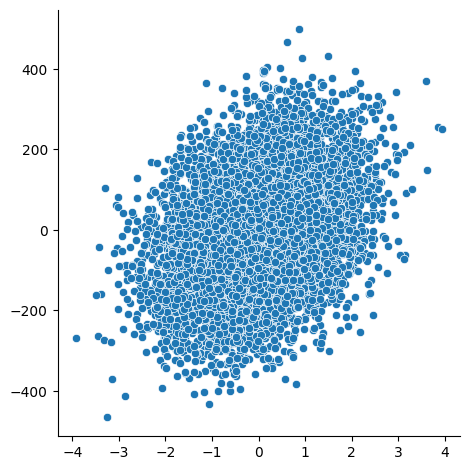

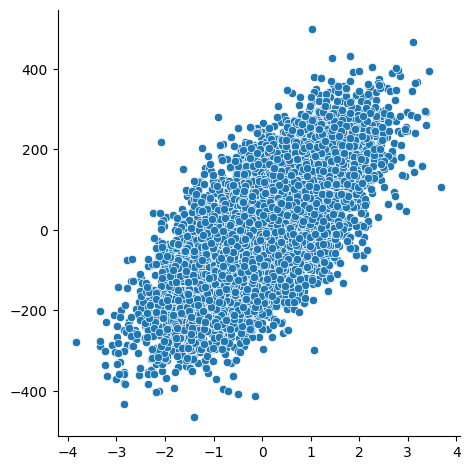

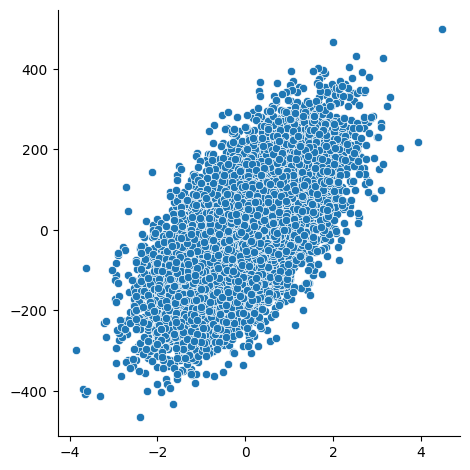

In [5]:
sns.relplot(x=x[:, 0], y=y, kind='scatter')
sns.relplot(x=x[:, 1], y=y, kind='scatter')
sns.relplot(x=x[:, 2], y=y, kind='scatter')

In [6]:
from sklearn.model_selection import train_test_split

X_train,x_test,Y_train,y_test=train_test_split(x,y,test_size=0.3,random_state=42)

# print(len(X_train),len(Y_train))

In [7]:
class MomentumSGD:
  def __init__(self,m=None,c=0,lr=0.0001,beta=0.5,epochs=50):
      self.m=m
      self.c=c
      self.lr=lr
      self.beta=beta
      self.vel_c=0
      self.vel_m=None
      self.epoch=epochs

  def fit(self,x,y):
    self.m=np.zeros(x.shape[1])
    self.vel_m = np.zeros(x.shape[1])  # Add this line
    for _ in range(self.epoch):

      for i in range(x.shape[0]):

        x_i=x[i]
        y_i=y[i]

        y_hat = self.c + (x_i @ self.m)

        # Calculate gradient of the loss with respect to intercept (c)
        dc = -2 *(y_i - y_hat)

        # Calculate gradient of the loss with respect to coefficients (m)
        dm = -2 * ((y_i - y_hat) * x_i)

        #Calculating the velocity
        self.vel_c= self.vel_c * self.beta + dc
        self.vel_m= self.vel_m * self.beta + dm

        # Update intercept using the learning rate
        self.c = self.c - (self.lr * self.vel_c)

        # Update coefficients using the learning rate
        self.m = self.m - (self.lr * self.vel_m)

  def predict(self,x_test):
    # Formula: y = mx + c
    return (x_test @ self.m) + self.c

In [8]:
from sklearn.linear_model import LinearRegression

lr=LinearRegression()
lr.fit(X_train,Y_train)
print("cofficents are ",lr.coef_)
print("intercept is",lr.intercept_)
print(lr.predict(x_test))

cofficents are  [43.32492571 88.16711621 83.18805164]
intercept is 0.0013884060104775164
[ 134.97312025  108.7314771    27.35777585 ...  -76.25808954 -125.94594594
   94.19709132]


In [16]:
test_obj=MomentumSGD()
test_obj.fit(X_train,Y_train)
print("cofficents are ",test_obj.m)
print("intercept is",test_obj.c)
print(test_obj.predict(x_test))

cofficents are  [43.32447891 88.16721213 83.18902836]
intercept is -0.002246229936698655
[ 134.97037566  108.72838262   27.35276658 ...  -76.26250926 -125.94891258
   94.19446897]


# NAG(Nesterov Accelerated Gradient)
Why Use Momentum?
Traditional gradient descent methods can be slow, especially when optimizing complex neural networks. To speed things up, momentum is introduced to keep the model moving in the same direction as the previous steps, thereby helping it overcome areas of slow progress.

Momentum optimization works by adjusting the weights based on both the current gradient and a fraction of the past gradients. This helps prevent oscillations around the optimal value, allowing for smoother and faster convergence. However, even momentum has limitations, particularly when navigating complex error surfaces with multiple valleys and peaks.

Enter Nesterov Accelerated Gradient (NAG)
Nesterov Accelerated Gradient is a refined version of momentum-based optimization, designed to further smooth and speed up convergence. It does so by looking ahead at the future gradient and adjusting accordingly, which helps reduce overshooting and improves stability.

In simple terms, NAG calculates the gradient at a “look-ahead” position rather than the current position. This look-ahead step is what makes NAG more effective at navigating tricky error surfaces, especially in non-convex optimization problems.

# The key concept to remember
Momentum: Where am I, and what is the gradient here?

NAG: Where will momentum take me? Let me calculate the gradient there before updating.

Remember this distinction:
- Momentum: Calculates the gradient where the parameters currently are.
- NAG: Calculates the gradient where momentum is expected to take the parameters.

Step 1: Calculate the lookahead position

-> **parameter_lookahead(t)=parameter(t-1) - learning_rate * beta * velocity(t-1)**


Step 2: Calculate the gradient at the lookahead position

Step 3: Update velocity

->  **velocity(t)=beta * velocity(t-1) + gradient_at_time(t)**

Step 4: Update parameters

-> **parameter(t) = parameter(t-1) + learning_rate * velocity(t)**

In [13]:
class NAG:
  def __init__(self,m=None,c=0,lr=0.0001,beta=0.5,epochs=50):
      self.m=m
      self.c=c
      self.lr=lr
      self.beta=beta
      self.vel_c=0
      self.vel_m=None
      self.epoch=epochs
      self.look_m=None
      self.look_c=0

  def fit(self,x,y):
    self.m=np.zeros(x.shape[1])
    self.look_m=np.zeros(x.shape[1])
    self.vel_m = np.zeros(x.shape[1])  # Add this line

    for _ in range(self.epoch):

      for i in range(x.shape[0]):

        x_i=x[i]
        y_i=y[i]

        self.look_m=self.m - self.lr * self.beta * self.vel_m
        self.look_c=self.c - self.lr * self.beta * self.vel_c

        y_hat = self.look_c + (x_i @ self.look_m)

        # Calculate gradient of the loss with respect to intercept (c)
        dc = -2 *(y_i - y_hat)

        # Calculate gradient of the loss with respect to coefficients (m)
        dm = -2 * ((y_i - y_hat) * x_i)

        #Calculating the velocity
        self.vel_c= self.vel_c * self.beta + dc
        self.vel_m= self.vel_m * self.beta + dm

        # Update intercept using the learning rate
        self.c = self.c - (self.lr * self.vel_c)

        # Update coefficients using the learning rate
        self.m = self.m - (self.lr * self.vel_m)

  def predict(self,x_test):
    # Formula: y = mx + c
    return (x_test @ self.m) + self.c

In [15]:
NAG_obj=NAG()
NAG_obj.fit(X_train,Y_train)
print(NAG_obj.predict(x_test))

[ 134.97037571  108.72838415   27.35276785 ...  -76.2625071  -125.94891348
   94.19446846]
